<a href="https://colab.research.google.com/github/juanrios0283-commits/Energia-Circular-5.0/blob/main/Autogeneraci%C3%B3n_Solar_Fotovoltaica_en_Popay%C3%A1n%2C_Cauca.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [19]:
# ============================================================
# INSTALACIÓN DE DEPENDENCIAS
# ============================================================
!pip install -q gradio plotly scikit-learn pandas numpy matplotlib seaborn

import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (r2_score, mean_absolute_error, mean_squared_error,
                             accuracy_score, f1_score, classification_report,
                             confusion_matrix, silhouette_score)

import gradio as gr
import os

print("✅ Librerías cargadas correctamente")

✅ Librerías cargadas correctamente


In [20]:
# ============================================================
# CARGA DEL DATASET
# ============================================================
# Opción A: Subir archivos manualmente
from google.colab import files
print("📤 Sube el archivo dataset_solar_popayan.csv")
uploaded = files.upload()

# Opción B (alternativa): Montar Google Drive
# from google.colab import drive
# drive.mount('/content/drive')
# RUTA = '/content/drive/MyDrive/dataset_solar_popayan.csv'

# Cargar CSV (asume que se subió a /content/)
df = pd.read_csv("dataset_solar_popayan.csv")

print(f"\n✅ Dataset cargado: {df.shape[0]} hogares × {df.shape[1]} variables")
print("\n📋 Primeras 5 filas:")
df.head()

📤 Sube el archivo dataset_solar_popayan.csv


Saving dataset_solar_popayan.csv to dataset_solar_popayan (1).csv

✅ Dataset cargado: 1000 hogares × 99 variables

📋 Primeras 5 filas:


,id_hogar,comuna,barrio,estrato,tipo_vivienda,zona,num_personas,num_menores,num_adultos_mayores,ingreso_mensual_cop,...,nivel_apropiacion_tecnologica,tiene_internet,tiene_smartphone,interes_comunidad_energetica,conoce_reciclaje_paneles,dispuesto_instalar_paneles,principal_barrera,principal_motivacion,disposicion_pago_mensual_cop,prioridad_gobierno
0,H0001,Yanaconas,Vereda Primavera,2,Vivienda rural,Rural,1,0,0,1510000,...,Alto,Sí,Sí,Sí,No,Sí,Costo,Ambiente,25000,Financiación
1,H0002,Calibío,Vereda Primavera,1,Vivienda rural,Rural,6,4,0,500000,...,Bajo,No,No,Sí,Sí,No,Costo,Ahorro,0,Capacitación
2,H0003,Comuna 2,Los Naranjos,1,Casa,Urbana,4,1,0,800000,...,Alto,Sí,Sí,Sí,No,Sí,Desconocimiento,Comunidad,30000,Subsidios
3,H0004,Comuna 3,Los Cámbulos,3,Apartamento,Urbana,3,1,0,2450000,...,Medio,Sí,Sí,No,No,No,Confianza,Independencia,15000,Regulación
4,H0005,Santa Rosa,Vereda Los Pinos,1,Vivienda rural,Rural,5,3,0,590000,...,Medio,No,Sí,Sí,Sí,No,Desconocimiento,Comunidad,0,Capacitación


In [21]:
# ============================================================
# EXPLORACIÓN INICIAL
# ============================================================
print("=" * 60)
print("INFORMACIÓN GENERAL")
print("=" * 60)
print(f"Filas: {df.shape[0]}")
print(f"Columnas: {df.shape[1]}")
print(f"Valores nulos: {df.isna().sum().sum()}")
print(f"Valores duplicados: {df.duplicated().sum()}")

print("\n" + "=" * 60)
print("TIPOS DE DATOS")
print("=" * 60)
print(df.dtypes.value_counts())

print("\n" + "=" * 60)
print("ESTADÍSTICAS DESCRIPTIVAS (variables numéricas clave)")
print("=" * 60)
cols_key = ['estrato', 'num_personas', 'ingreso_mensual_cop', 'consumo_kwh_mes',
            'costo_factura_mes_cop', 'inversion_estimada_cop', 'ahorro_anual_cop',
            'retorno_simple_anios', 'vpn_10_anios_cop', 'tir_porcentaje']
print(df[cols_key].describe().round(2).T)

INFORMACIÓN GENERAL
Filas: 1000
Columnas: 99
Valores nulos: 0
Valores duplicados: 0

TIPOS DE DATOS
float64    40
int64      30
object     29
Name: count, dtype: int64

ESTADÍSTICAS DESCRIPTIVAS (variables numéricas clave)
                         count        mean         std         min  \
estrato                 1000.0        1.50        0.74        1.00   
num_personas            1000.0        3.80        1.68        1.00   
ingreso_mensual_cop     1000.0  1238430.00   904384.18   400000.00   
consumo_kwh_mes         1000.0      111.52       43.26       60.00   
costo_factura_mes_cop   1000.0    88400.55    41439.71    42000.00   
inversion_estimada_cop  1000.0  7072601.00  1090573.82  5004000.00   
ahorro_anual_cop        1000.0   747075.70   266991.38   403200.00   
retorno_simple_anios    1000.0       10.35        3.12        4.63   
vpn_10_anios_cop        1000.0 -1244040.00  1572011.92 -4814000.00   
tir_porcentaje          1000.0        6.22        4.46       -2.70   

      

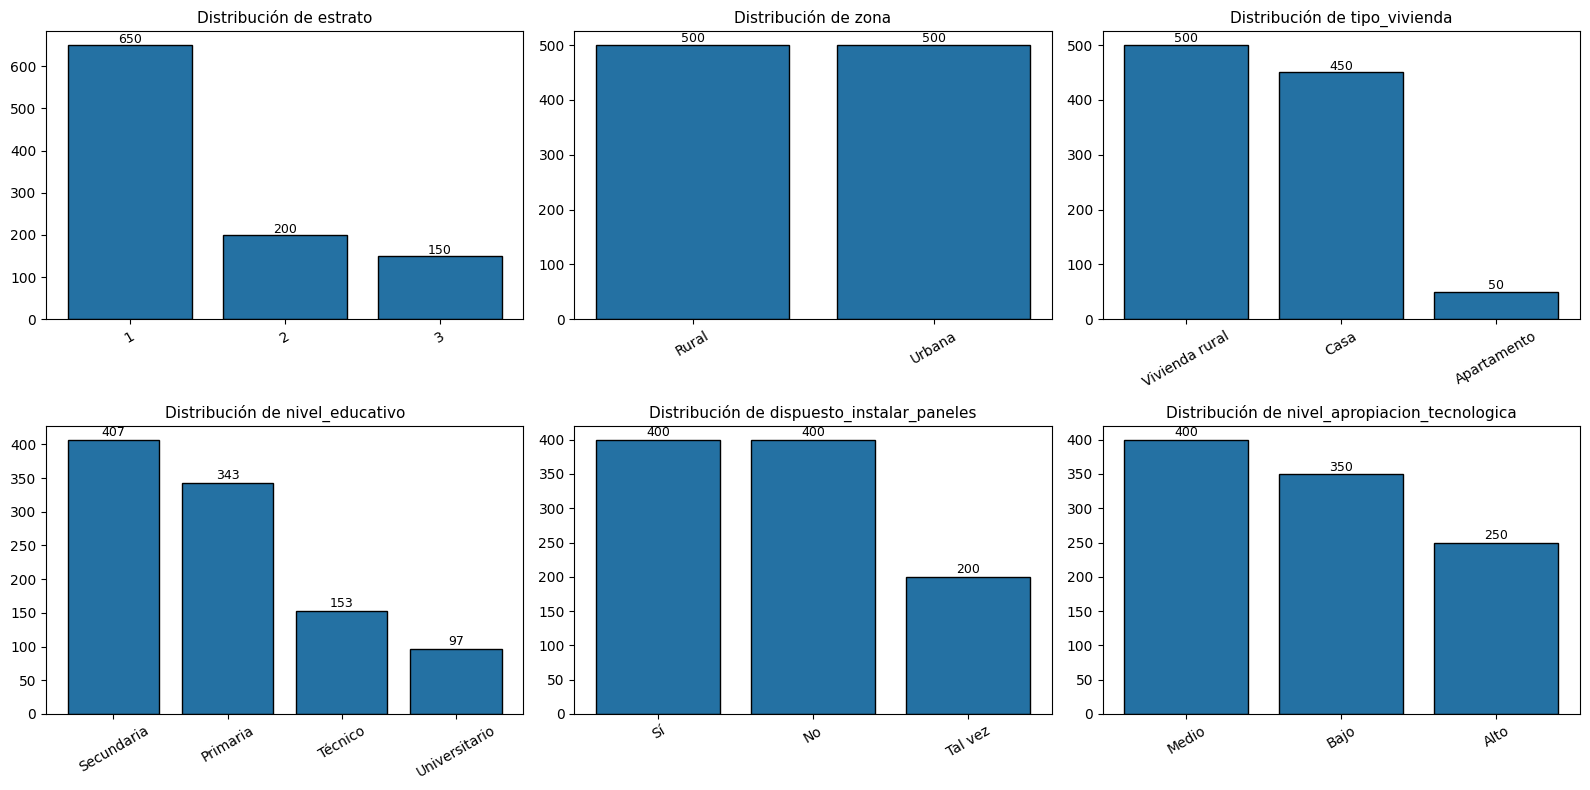

In [22]:
# ============================================================
# DISTRIBUCIÓN DE VARIABLES CATEGÓRICAS
# ============================================================
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

cat_vars = ['estrato', 'zona', 'tipo_vivienda', 'nivel_educativo',
            'dispuesto_instalar_paneles', 'nivel_apropiacion_tecnologica']

for i, var in enumerate(cat_vars):
    counts = df[var].value_counts()
    axes[i].bar(counts.index.astype(str), counts.values, color='#2471a3', edgecolor='black')
    axes[i].set_title(f'Distribución de {var}', fontsize=11)
    axes[i].tick_params(axis='x', rotation=30)
    for j, v in enumerate(counts.values):
        axes[i].text(j, v + 5, str(v), ha='center', fontsize=9)

plt.tight_layout()
plt.show()

In [23]:
# ============================================================
# CONSUMO POR ESTRATO (Boxplot interactivo con Plotly)
# ============================================================
fig = px.box(df, x='estrato', y='consumo_kwh_mes', color='estrato',
             title='Consumo eléctrico mensual por estrato (n=1.000 hogares)',
             labels={'estrato': 'Estrato', 'consumo_kwh_mes': 'Consumo (kWh/mes)'},
             color_discrete_sequence=px.colors.qualitative.Bold)
fig.update_layout(template='plotly_white', height=500)
fig.show()

# Resumen numérico
print("\n📊 Consumo promedio por estrato:")
print(df.groupby('estrato')['consumo_kwh_mes'].agg(['mean', 'median', 'std', 'min', 'max']).round(1))


📊 Consumo promedio por estrato:
          mean  median   std    min    max
estrato                                   
1         88.3    87.6  21.2   60.0  120.0
2        132.7   130.0  25.9  100.0  180.0
3        183.8   172.0  38.7  150.0  280.0


In [24]:
# ============================================================
# PERFIL HORARIO PROMEDIO POR ESTRATO
# ============================================================
H = [f"h{h:02d}" for h in range(24)]

fig = go.Figure()
colors = {1: '#c0392b', 2: '#e6a817', 3: '#2471a3'}
for s in [1, 2, 3]:
    sub = df[df['estrato'] == s]
    mean_hour = sub[H].mean().values * 1000  # Wh
    fig.add_trace(go.Scatter(x=list(range(24)), y=mean_hour,
                             mode='lines+markers', name=f'Estrato {s}',
                             line=dict(color=colors[s], width=3)))

fig.update_layout(title='Perfil horario promedio de demanda por estrato',
                  xaxis_title='Hora del día', yaxis_title='Consumo medio (Wh/hora)',
                  template='plotly_white', height=500)
fig.show()

In [25]:
# ============================================================
# MATRIZ DE CORRELACIÓN (variables clave)
# ============================================================
cols_corr = ['estrato', 'num_personas', 'ingreso_mensual_cop', 'area_vivienda_m2',
             'consumo_kwh_mes', 'costo_factura_mes_cop', 'generacion_potencial_kwp',
             'inversion_estimada_cop', 'ahorro_anual_cop', 'porcentaje_ahorro',
             'retorno_simple_anios', 'vpn_10_anios_cop', 'tir_porcentaje']

corr = df[cols_corr].corr()
fig = px.imshow(corr, text_auto='.2f', aspect='auto',
                color_continuous_scale='RdBu_r', zmin=-1, zmax=1,
                title='Matriz de correlación (variables clave)')
fig.update_layout(height=700, template='plotly_white')
fig.show()

In [26]:
# ============================================================
# DISPERSIÓN: INVERSIÓN VS AHORRO ANUAL
# ============================================================
fig = px.scatter(df, x='inversion_estimada_cop', y='ahorro_anual_cop',
                 color='estrato', size='num_paneles_estimados',
                 hover_data=['id_hogar', 'retorno_simple_anios', 'vpn_10_anios_cop'],
                 title='Inversión estimada vs ahorro anual (coloreado por estrato)',
                 labels={'inversion_estimada_cop': 'Inversión (COP)',
                         'ahorro_anual_cop': 'Ahorro anual (COP)'},
                 color_continuous_scale='Viridis')
fig.update_layout(template='plotly_white', height=550)
fig.show()

In [27]:
# ============================================================
# PREPROCESAMIENTO
# ============================================================
# Variables para clustering
cluster_vars = ['estrato', 'num_personas', 'ingreso_mensual_cop',
                'area_vivienda_m2', 'consumo_kwh_mes', 'costo_factura_mes_cop',
                'generacion_potencial_kwp', 'inversion_estimada_cop',
                'ahorro_anual_cop', 'porcentaje_ahorro', 'retorno_simple_anios']

X_cluster = df[cluster_vars].copy()
scaler_cluster = StandardScaler()
X_cluster_scaled = scaler_cluster.fit_transform(X_cluster)

print(f"✅ Matriz para clustering: {X_cluster_scaled.shape}")

✅ Matriz para clustering: (1000, 11)


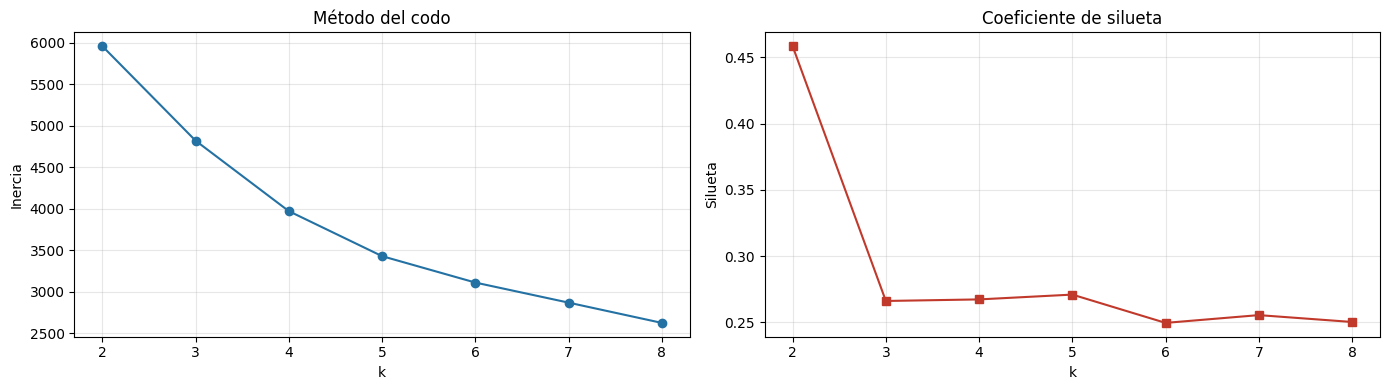


✅ k óptimo según silueta: 2


In [28]:
# ============================================================
# CLUSTERING: SELECCIÓN DE K ÓPTIMO
# ============================================================
inertias, silhouettes = [], []
K_range = range(2, 9)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_cluster_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_cluster_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(list(K_range), inertias, marker='o', color='#2471a3')
axes[0].set_title('Método del codo'); axes[0].set_xlabel('k'); axes[0].set_ylabel('Inercia')
axes[0].grid(alpha=0.3)

axes[1].plot(list(K_range), silhouettes, marker='s', color='#c0392b')
axes[1].set_title('Coeficiente de silueta'); axes[1].set_xlabel('k'); axes[1].set_ylabel('Silueta')
axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

best_k = list(K_range)[int(np.argmax(silhouettes))]
print(f"\n✅ k óptimo según silueta: {best_k}")

In [29]:
# ============================================================
# APLICAR KMEANS CON k ÓPTIMO + VISUALIZACIÓN PCA
# ============================================================
km_final = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df['cluster'] = km_final.fit_predict(X_cluster_scaled)

# PCA 2D
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_cluster_scaled)
df['pca1'], df['pca2'] = X_pca[:, 0], X_pca[:, 1]

fig = px.scatter(df, x='pca1', y='pca2', color=df['cluster'].astype(str),
                 title=f'Clusters de hogares (KMeans k={best_k}, PCA 2D)',
                 labels={'color': 'Cluster'},
                 color_discrete_sequence=px.colors.qualitative.Set2,
                 hover_data=['id_hogar', 'estrato', 'consumo_kwh_mes'])
fig.update_layout(template='plotly_white', height=550)
fig.show()

# Perfil promedio por cluster
print("\n📊 Perfil promedio por cluster:")
print(df.groupby('cluster')[cluster_vars].mean().round(1))


📊 Perfil promedio por cluster:
         estrato  num_personas  ingreso_mensual_cop  area_vivienda_m2  \
cluster                                                                 
0            1.1           3.9             793766.9              64.6   
1            2.6           3.5            2490954.2              98.4   

         consumo_kwh_mes  costo_factura_mes_cop  generacion_potencial_kwp  \
cluster                                                                     
0                   90.9                67888.2                       1.4   
1                  169.7               146179.6                       1.6   

         inversion_estimada_cop  ahorro_anual_cop  porcentaje_ahorro  \
cluster                                                                
0                     6828928.2          622513.1               77.2   
1                     7758977.1         1097942.9               63.4   

         retorno_simple_anios  
cluster                        
0            

In [30]:
# ============================================================
# REGRESIÓN: PREDECIR AHORRO ANUAL
# ============================================================
reg_features = ['estrato', 'num_personas', 'ingreso_mensual_cop',
                'area_vivienda_m2', 'consumo_kwh_mes', 'costo_factura_mes_cop',
                'generacion_potencial_kwp', 'num_paneles_estimados',
                'radiacion_promedio_kwh_m2_dia']

X_reg = df[reg_features]
y_reg = df['ahorro_anual_cop']

X_train, X_test, y_train, y_test = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

rf_reg = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf_reg.fit(X_train, y_train)

y_pred = rf_reg.predict(X_test)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("=" * 60)
print("REGRESIÓN — Random Forest (ahorro_anual_cop)")
print("=" * 60)
print(f"R²   : {r2:.4f}")
print(f"MAE  : {mae:,.0f} COP")
print(f"RMSE : {rmse:,.0f} COP")

# Importancia de variables
imp = pd.DataFrame({'Variable': reg_features, 'Importancia': rf_reg.feature_importances_})
imp = imp.sort_values('Importancia', ascending=True)
fig = px.bar(imp, x='Importancia', y='Variable', orientation='h',
             title='Importancia de variables — Random Forest (regresión)',
             color='Importancia', color_continuous_scale='Blues')
fig.update_layout(template='plotly_white', height=500)
fig.show()

# Predicho vs real
fig2 = px.scatter(x=y_test, y=y_pred, opacity=0.5,
                  labels={'x': 'Ahorro real (COP)', 'y': 'Ahorro predicho (COP)'},
                  title=f'Ahorro real vs predicho (R²={r2:.3f})')
fig2.add_shape(type='line', x0=y_test.min(), y0=y_test.min(),
               x1=y_test.max(), y1=y_test.max(),
               line=dict(color='red', dash='dash'))
fig2.update_layout(template='plotly_white', height=500)
fig2.show()

REGRESIÓN — Random Forest (ahorro_anual_cop)
R²   : 0.9742
MAE  : 25,402 COP
RMSE : 44,615 COP


In [31]:
# ============================================================
# CLASIFICACIÓN: DISPOSICIÓN A INSTALAR PANELES
# ============================================================
clf_features = ['estrato', 'num_personas', 'ingreso_mensual_cop',
                'area_vivienda_m2', 'consumo_kwh_mes', 'costo_factura_mes_cop',
                'porcentaje_ahorro', 'retorno_simple_anios', 'vpn_10_anios_cop',
                'tir_porcentaje', 'nivel_apropiacion_tecnologica']

df_clf = df[clf_features + ['dispuesto_instalar_paneles']].copy()
le_aprop = LabelEncoder()
df_clf['nivel_apropiacion_tecnologica'] = le_aprop.fit_transform(df_clf['nivel_apropiacion_tecnologica'])

le_target = LabelEncoder()
y_clf = le_target.fit_transform(df_clf['dispuesto_instalar_paneles'])
X_clf = df_clf[clf_features]

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf)

rf_clf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf_clf.fit(X_train_c, y_train_c)
y_pred_c = rf_clf.predict(X_test_c)

acc = accuracy_score(y_test_c, y_pred_c)
f1 = f1_score(y_test_c, y_pred_c, average='weighted')

print("=" * 60)
print("CLASIFICACIÓN — Random Forest (dispuesto_instalar_paneles)")
print("=" * 60)
print(f"Accuracy : {acc:.4f}")
print(f"F1-score : {f1:.4f}")
print("\nReporte por clase:")
print(classification_report(y_test_c, y_pred_c, target_names=le_target.classes_))

# Matriz de confusión
cm = confusion_matrix(y_test_c, y_pred_c)
fig = px.imshow(cm, text_auto=True, aspect='auto',
                x=le_target.classes_, y=le_target.classes_,
                labels=dict(x='Predicho', y='Real'),
                title='Matriz de confusión', color_continuous_scale='Blues')
fig.update_layout(template='plotly_white', height=450)
fig.show()

CLASIFICACIÓN — Random Forest (dispuesto_instalar_paneles)
Accuracy : 0.5850
F1-score : 0.5659

Reporte por clase:
              precision    recall  f1-score   support

          No       0.62      0.69      0.65        80
          Sí       0.61      0.69      0.65        80
     Tal vez       0.32      0.17      0.23        40

    accuracy                           0.58       200
   macro avg       0.52      0.52      0.51       200
weighted avg       0.56      0.58      0.57       200



In [32]:
# ============================================================
# APLICACIÓN GRADIO — 6 PESTAÑAS
# ============================================================
H = [f"h{h:02d}" for h in range(24)]

# ---------- Funciones auxiliares ----------
def get_hogar(id_hogar):
    row = df[df['id_hogar'] == id_hogar].iloc[0]
    return row

def grafico_perfil_hogar(id_hogar):
    row = get_hogar(id_hogar)
    horas = list(range(24))
    valores = [row[f"h{h:02d}"] * 1000 for h in horas]  # Wh
    fig = go.Figure()
    fig.add_trace(go.Bar(x=horas, y=valores, marker_color='#2471a3'))
    fig.update_layout(title=f'Perfil horario — {id_hogar}',
                      xaxis_title='Hora', yaxis_title='Wh/hora',
                      template='plotly_white', height=350)
    return fig

def consulta_hogar(id_hogar):
    row = get_hogar(id_hogar)
    resumen = f"""
### 🏠 Hogar {row['id_hogar']} — {row['comuna']}, {row['barrio']}

**Características socioeconómicas:**
- **Estrato:** {row['estrato']} | **Zona:** {row['zona']} | **Tipo vivienda:** {row['tipo_vivienda']}
- **Personas:** {row['num_personas']} | **Ingreso mensual:** ${row['ingreso_mensual_cop']:,.0f} COP
- **Educación:** {row['nivel_educativo']} | **Ocupación:** {row['ocupacion_principal']}

**Consumo y facturación:**
- **Consumo mensual:** {row['consumo_kwh_mes']:.1f} kWh
- **Factura mensual:** ${row['costo_factura_mes_cop']:,.0f} COP (tarifa: {row['tarifa_kwh_cop']} COP/kWh)
- **Recibe subsidio:** {row['recibe_subsidio']} | **Medidor inteligente:** {row['tiene_medidor_inteligente']}

**Potencial solar:**
- **Radiación:** {row['radiacion_promedio_kwh_m2_dia']} kWh/m²/día
- **Generación potencial:** {row['generacion_potencial_kwp']} kWp
- **Paneles estimados:** {row['num_paneles_estimados']} × {row['potencia_panel_w']} W
- **Generación mensual:** {row['generacion_mensual_estimada_kwh']:.1f} kWh

**Análisis financiero:**
- **Inversión:** ${row['inversion_estimada_cop']:,.0f} COP
- **Ahorro mensual:** ${row['ahorro_mensual_cop']:,.0f} COP ({row['porcentaje_ahorro']}%)
- **Retorno simple:** {row['retorno_simple_anios']} años
- **VPN (10 años):** ${row['vpn_10_anios_cop']:,.0f} COP
- **TIR:** {row['tir_porcentaje']}%
- **Requiere financiación:** {row['requiere_financiacion']} ({row['fuente_financiacion']})

**Componente IA y economía circular:**
- **Cluster:** {row['cluster']}
- **Dispositivo IA de interés:** {row['dispositivo_ia_interes']}
- **Apropiación tecnológica:** {row['nivel_apropiacion_tecnologica']}
- **Interés en comunidad energética:** {row['interes_comunidad_energetica']}
- **Conoce reciclaje de paneles:** {row['conoce_reciclaje_paneles']}
- **Barrera principal:** {row['principal_barrera']} | **Motivación:** {row['principal_motivacion']}
"""
    return resumen

def simulador(n_paneles, potencia_panel, tarifa, tasa_desc, costo_kwp):
    kwp = n_paneles * potencia_panel / 1000
    hsp = 4.324  # horas sol pico promedio
    PR = 0.80
    gen_dia = kwp * hsp * PR
    gen_mes = gen_dia * 30
    gen_anual = gen_dia * 365
    inversion = kwp * costo_kwp
    # Supuestos: autoconsumo 70%, excedentes 30% (valor 35% tarifa)
    autoconsumo = gen_anual * 0.70
    excedentes = gen_anual * 0.30
    ahorro_anual = autoconsumo * tarifa + excedentes * tarifa * 0.35
    ahorro_mensual = ahorro_anual / 12
    retorno_meses = inversion / ahorro_mensual if ahorro_mensual > 0 else 0
    retorno_anios = retorno_meses / 12
    # VPN
    cf = [-inversion] + [ahorro_anual * (1.05 ** (t - 1)) * (0.995 ** (t - 1)) - 0.01 * inversion for t in range(1, 11)]
    vpn = sum(c / (1 + tasa_desc) ** t for t, c in enumerate(cf))
    # TIR aproximada
    def tir(cf):
        lo, hi = -0.5, 1.0
        for _ in range(100):
            mid = (lo + hi) / 2
            if sum(c / (1 + mid) ** t for t, c in enumerate(cf)) > 0:
                lo = mid
            else:
                hi = mid
        return (lo + hi) / 2
    tir_val = tir(cf) * 100

    resumen = f"""
### 🔧 Resultados de la simulación

- **Potencia instalada:** {kwp:.2f} kWp
- **Generación diaria:** {gen_dia:.2f} kWh/día
- **Generación mensual:** {gen_mes:.1f} kWh/mes
- **Generación anual:** {gen_anual:.0f} kWh/año
- **Inversión:** ${inversion:,.0f} COP
- **Ahorro mensual:** ${ahorro_mensual:,.0f} COP
- **Ahorro anual:** ${ahorro_anual:,.0f} COP
- **Retorno simple:** {retorno_anios:.2f} años ({retorno_meses:.0f} meses)
- **VPN (10 años, tasa {tasa_desc*100:.0f}%):** ${vpn:,.0f} COP
- **TIR:** {tir_val:.2f}%
"""
    return resumen

def grafico_clusters():
    fig = px.scatter(df, x='pca1', y='pca2', color=df['cluster'].astype(str),
                     title=f'Clusters de hogares (k={best_k})',
                     labels={'color': 'Cluster'},
                     color_discrete_sequence=px.colors.qualitative.Set2)
    fig.update_layout(template='plotly_white', height=500)
    return fig

def tabla_clusters():
    return df.groupby('cluster')[cluster_vars].mean().round(1).reset_index()

def recomendaciones(id_hogar):
    row = get_hogar(id_hogar)
    disp = row['dispuesto_instalar_paneles']
    rec = f"""
### 🎯 Recomendaciones personalizadas para {row['id_hogar']}

**Disposición declarada:** {disp}

**Recomendación técnica:**
- Sistema sugerido: {row['num_paneles_estimados']} paneles × {row['potencia_panel_w']} W ({row['generacion_potencial_kwp']} kWp)
- Generación estimada: {row['generacion_mensual_estimada_kwh']:.1f} kWh/mes

**Recomendación financiera:**
- Ahorro proyectado: ${row['ahorro_mensual_cop']:,.0f} COP/mes
- Retorno: {row['retorno_simple_anios']} años
- {'✅ Inversión viable (VPN > 0)' if row['vpn_10_anios_cop'] > 0 else '⚠️ Inversión no viable a 10 años — considerar subsidios o financiación'}

**Componente IA recomendado:** {row['dispositivo_ia_interes']}

**Economía circular:**
- {'✅ Conoce el reciclaje de paneles' if row['conoce_reciclaje_paneles'] == 'Sí' else '📚 Se recomienda capacitación en gestión de RAEE'}
- Participación en comunidad energética: {row['interes_comunidad_energetica']}

**Barrera principal:** {row['principal_barrera']}
**Motivación principal:** {row['principal_motivacion']}
**Prioridad de gobierno sugerida:** {row['prioridad_gobierno']}
"""
    return rec

# ---------- Interfaz Gradio ----------
with gr.Blocks(theme=gr.themes.Soft(), title="Autogeneración Solar Popayán") as app:
    gr.Markdown("# 🌞 Autogeneración Solar Fotovoltaica en Popayán, Cauca")
    gr.Markdown("*Diplomado en Energía Circular Inteligente 5.0 — Proyecto Integrador*")

    with gr.Tabs():
        # --- Pestaña 1: Inicio ---
        with gr.Tab("🏠 Inicio"):
            gr.Markdown("""
            ## Bienvenido
            Esta aplicación permite explorar el dataset sintético de **1.000 hogares de Popayán**
            y analizar la viabilidad de la autogeneración solar fotovoltaica residencial.

            ### Contexto
            - **Territorio:** Popayán, Cauca, Colombia
            - **Radiación solar:** 4.25 kWh/m²/día (UPME-IDEAM)
            - **Estratos analizados:** 1, 2 y 3
            - **Enfoque:** Transición energética justa + IA + economía circular

            ### Módulos
            1. **Dashboard** — visualizaciones generales.
            2. **Consulta por hogar** — análisis detallado.
            3. **Simulador** — escenarios personalizados.
            4. **Clustering** — segmentación de hogares.
            5. **Recomendaciones** — sugerencias personalizadas.

            > ⚠️ Datos sintéticos calibrados con rangos reales (DANE, UPME-IDEAM, Ley 142/1994).
            """)

        # --- Pestaña 2: Dashboard ---
        with gr.Tab("📊 Dashboard"):
            gr.Markdown("## Visualizaciones generales del dataset")
            with gr.Row():
                fig1 = px.box(df, x='estrato', y='consumo_kwh_mes', color='estrato',
                              title='Consumo mensual por estrato')
                fig1.update_layout(template='plotly_white', height=400, showlegend=False)
                gr.Plot(fig1)
                fig2 = px.histogram(df, x='porcentaje_ahorro', nbins=30,
                                    title='Distribución del % de ahorro',
                                    color_discrete_sequence=['#2471a3'])
                fig2.update_layout(template='plotly_white', height=400)
                gr.Plot(fig2)
            fig3 = px.histogram(df, x='retorno_simple_anios', nbins=30,
                                title='Distribución del retorno simple (años)',
                                color_discrete_sequence=['#c0392b'])
            fig3.update_layout(template='plotly_white', height=400)
            gr.Plot(fig3)

        # --- Pestaña 3: Consulta por hogar ---
        with gr.Tab("🔍 Consulta por hogar"):
            gr.Markdown("## Análisis detallado de un hogar")
            dropdown_hogar = gr.Dropdown(choices=sorted(df['id_hogar'].tolist()),
                                         value=df['id_hogar'].iloc[0],
                                         label="Selecciona un hogar")
            btn_consultar = gr.Button("🔎 Consultar", variant="primary")
            salida_texto = gr.Markdown()
            salida_grafico = gr.Plot()

            btn_consultar.click(fn=consulta_hogar, inputs=dropdown_hogar, outputs=salida_texto)
            btn_consultar.click(fn=grafico_perfil_hogar, inputs=dropdown_hogar, outputs=salida_grafico)

        # --- Pestaña 4: Simulador ---
        with gr.Tab("🔧 Simulador"):
            gr.Markdown("## Simulador de sistema fotovoltaico")
            with gr.Row():
                n_pan = gr.Slider(3, 12, value=4, step=1, label="Número de paneles")
                pot_pan = gr.Slider(400, 550, value=500, step=25, label="Potencia por panel (W)")
            with gr.Row():
                tar = gr.Slider(700, 950, value=800, step=10, label="Tarifa (COP/kWh)")
                tasa = gr.Slider(0.08, 0.12, value=0.10, step=0.01, label="Tasa de descuento")
            ckwp = gr.Slider(3_500_000, 5_000_000, value=4_500_000, step=100_000,
                             label="Costo por kWp (COP)")
            btn_sim = gr.Button("⚙️ Simular", variant="primary")
            salida_sim = gr.Markdown()

            btn_sim.click(fn=simulador,
                          inputs=[n_pan, pot_pan, tar, tasa, ckwp],
                          outputs=salida_sim)

        # --- Pestaña 5: Clustering ---
        with gr.Tab("🎯 Clustering"):
            gr.Markdown("## Segmentación de hogares (KMeans + PCA)")
            gr.Plot(grafico_clusters())
            gr.Markdown("### Perfil promedio por cluster")
            gr.Dataframe(tabla_clusters())

        # --- Pestaña 6: Recomendaciones ---
        with gr.Tab("💡 Recomendaciones"):
            gr.Markdown("## Recomendaciones personalizadas")
            dropdown_rec = gr.Dropdown(choices=sorted(df['id_hogar'].tolist()),
                                       value=df['id_hogar'].iloc[0],
                                       label="Selecciona un hogar")
            btn_rec = gr.Button("💡 Generar recomendaciones", variant="primary")
            salida_rec = gr.Markdown()
            btn_rec.click(fn=recomendaciones, inputs=dropdown_rec, outputs=salida_rec)

print("✅ Aplicación Gradio construida correctamente")

✅ Aplicación Gradio construida correctamente


In [33]:
# ============================================================
# LANZAR APLICACIÓN GRADIO
# ============================================================
app.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c79a1d56fa09d037bf.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
